# Practical Exam: House sales

RealAgents is a real estate company that focuses on selling houses.

RealAgents sells a variety of types of house in one metropolitan area.

Some houses sell slowly and sometimes require lowering the price in order to find a buyer.

In order to stay competitive, RealAgents would like to optimize the listing prices of the houses it is trying to sell.

They want to do this by predicting the sale price of a house given its characteristics.

If they can predict the sale price in advance, they can decrease the time to sale.


## Data

The dataset contains records of previous houses sold in the area.

| Column Name | Criteria                                                |
|-------------|---------------------------------------------------------|
| house_id    | Nominal. </br> Unique identifier for houses. </br>Missing values not possible. |
| city        | Nominal. </br>The city in which the house is located. One of 'Silvertown', 'Riverford', 'Teasdale' and 'Poppleton'. </br>Replace missing values with "Unknown". |
| sale_price  | Discrete. </br>The sale price of the house in whole dollars. Values can be any positive number greater than or equal to zero.</br>Remove missing entries. |
| sale_date   | Discrete. </br>The date of the last sale of the house. </br>Replace missing values with 2023-01-01. |
| months_listed  | Continuous. </br>The number of months the house was listed on the market prior to its last sale, rounded to one decimal place. </br>Replace missing values with mean number of months listed, to one decimal place. |
| bedrooms    | Discrete. </br>The number of bedrooms in the house. Any positive values greater than or equal to zero. </br>Replace missing values with the mean number of bedrooms, rounded to the nearest integer. |
| house_type   | Ordinal. </br>One of "Terraced" (two shared walls), "Semi-detached" (one shared wall), or "Detached" (no shared walls). </br>Replace missing values with the most common house type. |
| area      | Continuous. </br>The area of the house in square meters, rounded to one decimal place. </br>Replace missing values with the mean, to one decimal place. |


# Preliminaries
_This is being updated as we go along..._

In [1]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

In [2]:
# configuring plot rendering
sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'text.usetex': False,
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
})

In [3]:
# loading dataset
df = pd.read_csv('house_sales.csv')

# initial inspection of dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   house_id       1500 non-null   int64  
 1   city           1500 non-null   object 
 2   sale_price     1500 non-null   int64  
 3   sale_date      1500 non-null   object 
 4   months_listed  1469 non-null   float64
 5   bedrooms       1500 non-null   int64  
 6   house_type     1500 non-null   object 
 7   area           1500 non-null   object 
dtypes: float64(1), int64(3), object(4)
memory usage: 93.9+ KB


# Task 1

The team at RealAgents knows that the city that a property is located in makes a difference to the sale price. 

Unfortuntately they believe that this isn't always recorded in the data. 

Calculate the number of missing values of the `city`. 

 - You should use the data in the file "house_sales.csv". 

 - Your output should be an object `missing_city`, that contains the number of missing values in this column. 

In [4]:
# calculating missing vals in column 'city'
missing_city = df['city'].isna().sum()

missing_city.item()

0

The output above returned `0`. However, the prompt for task 1 explicitly states
> _"The team... believes that this isn't always recorded in the data."_

Furthermore, looking at the output of `df.info()` earlier, we see that the column `area` stores `object` (string) entries, when it can be inferred to rather contain continuous float data.

## Diagnostic (pre-cleaning)
Before executing the formal cleaning operations for the succeeding task, we must inspect the unique values within the categorical columns and the string-polluted numerical columns.

This will expose any hard-coded missing values (e.g., dashes, typos) that the method `.isna()` fails to detect.

In [5]:
# checking unique vals
## in 'city'
print(df['city'].value_counts(dropna=False))
## in 'house_type'
print(df['house_type'].value_counts(dropna=False))

city
Silvertown    517
Teasdale      366
Poppleton     362
Riverford     182
--             73
Name: count, dtype: int64
house_type
Detached         1046
Semi-detached     231
Terraced          123
Det.               78
Semi               14
Terr.               8
Name: count, dtype: int64


In [6]:
# inspecting sample of column 'area'
print(df['area'].head(15))

# checking for exact strings in 'area' that might repr. nulls
print(df[~df['area'].str.replace('.', '', regex=False).str.isnumeric()]['area'].value_counts())

0     107.8 sq.m.
1     498.8 sq.m.
2     542.5 sq.m.
3     528.4 sq.m.
4     477.1 sq.m.
5     123.2 sq.m.
6     544.6 sq.m.
7     371.3 sq.m.
8     125.7 sq.m.
9     371.5 sq.m.
10    428.8 sq.m.
11    147.7 sq.m.
12    395.6 sq.m.
13    304.4 sq.m.
14    316.8 sq.m.
Name: area, dtype: object
area
124.3 sq.m.    4
424.8 sq.m.    3
408.3 sq.m.    3
554.9 sq.m.    3
169.5 sq.m.    3
              ..
371.5 sq.m.    1
125.7 sq.m.    1
371.3 sq.m.    1
544.6 sq.m.    1
123.2 sq.m.    1
Name: count, Length: 1282, dtype: int64


Based on these outputs, we can observe three (3) explicit contamination vectors:
1. `city`: the missing values are hard-coded as the string `'--'`, accounting for 73 entries (this, then, becomes our expected `missing_city` output);
2. `house_type`: there are inconsistent categorical abbreviations (`'Det.'`, `'Semi'`, and `'Terr.'`) that must be mapped to their full string equivalents; and
3. `area`: the numeric data are polluted by the suffix `' sq.m.'`, forcing `pandas` to interpret the column as a string.

## Correction (for true missing values)
Since the method `.isna()` looks _specifically_ for `np.nan` or `None`, it bypassed the `'--'` strings. We apply a boolean mask checking for this string.

In [7]:
# calculating true num of missing vals in column 'city'
missing_city = (df['city'] == '--').sum()

missing_city.item()

73

The variable `missing_city` now holds a value that matches the number of instances of `'--'` in the column `city`, and we proceed to the next task.

# Task 2 

Before you fit any models, you will need to make sure the data is clean. 

The table below shows what the data should look like. 

Create a cleaned version of the dataframe. 

 - You should start with the data in the file "house_sales.csv". 

 - Your output should be a dataframe named `clean_data`. 

 - All column names and values should match the table below.


| Column Name | Criteria                                                |
|-------------|---------------------------------------------------------|
| house_id    | Nominal. </br> Unique identifier for houses. </br>Missing values not possible. |
| city        | Nominal. </br>The city in which the house is located. One of 'Silvertown', 'Riverford', 'Teasdale' and 'Poppleton' </br>Replace missing values with "Unknown". |
| sale_price  | Discrete. </br>The sale price of the house in whole dollars. Values can be any positive number greater than or equal to zero.</br>Remove missing entries. |
| sale_date   | Discrete. </br>The date of the last sale of the house. </br>Replace missing values with 2023-01-01. |
| months_listed  | Continuous. </br>The number of months the house was listed on the market prior to its last sale, rounded to one decimal place. </br>Replace missing values with mean number of months listed, to one decimal place. |
| bedrooms    | Discrete. </br>The number of bedrooms in the house. Any positive values greater than or equal to zero. </br>Replace missing values with the mean number of bedrooms, rounded to the nearest integer. |
| house_type   | Ordinal. </br>One of "Terraced", "Semi-detached", or "Detached". </br>Replace missing values with the most common house type. |
| area      | Continuous. </br>The area of the house in square meters, rounded to one decimal place. </br>Replace missing values with the mean, to one decimal place. |

## Data cleaning and type conversion
We transform `df` into `clean_data` by enforcing the schema defined in the data dictionary.

First, we initialise our working dataframe and handle the strict requirements for our target variable, `sale_price`, which prohibits missing entries.

In [8]:
# initialising clean_data object
clean_data = df.copy()

# removing any missing records
clean_data = clean_data.dropna(subset=['sale_price'])

### Categorical
The diagnostic done earlier in task 1 revealed the contamination in the categorical features `city` and `house_type`.

We will map these to their formal strings and apply the required imputation logic (filling missing cities with `'Unknown'` and missing house types with the most common entry).

In [9]:
# parsing and imputing 'city'
clean_data['city'] = clean_data['city'].replace('--', 'Unknown').fillna('Unknown')

# defining map for 'house_type'
type_dict = {
    'Det.': 'Detached',
    'Semi': 'Semi-detached',
    'Terr.': 'Terraced'
}
clean_data['house_type'] = clean_data['house_type'].replace(type_dict)
# imputing remaining nulls with mode
type_mode = clean_data['house_type'].mode()[0]
clean_data['house_type'] = clean_data['house_type'].fillna(type_mode)

### Temporal and discrete numeric
During our preliminary diagnostic, `df.info()`, in the preliminaries section, both `sale_price` and `bedrooms` registered cleanly as `int64`, and `months_listed` as `float64`. This guarantees us that these columns contain absolutely no string contamination (e.g., hidden dashes or text). Had even a single row contained a string, `pandas` would have coerced the entire column to an `object` type (as it did with `area`).

Because the data structures here are purely numeric, standard `pandas` methods will perfectly isolate the missing data, and there is no more need to hunt for inconsistencies.

For imputation:
* `sale_date`: the fallback is explicitly defined as `2023-01-01`; and
* `months_listed` & `bedrooms`: missing values must be imputed with their respective means, where we apply the given strict rounding constraints (one decimal place for continuous months, and nearest integer for discrete bedrooms).

In [10]:
# handling temporal data in 'sale_date'
clean_data['sale_date'] = clean_data['sale_date'].fillna('2023-01-01')

# computing and applying rounded mean for 'months_listed'
month_mean = round(clean_data['months_listed'].mean(), 1)
clean_data['months_listed'] = clean_data['months_listed'].fillna(month_mean)

# computing and applying rounded mean for 'bedrooms'
bed_mean = int(round(clean_data['bedrooms'].mean()))
clean_data['bedrooms'] = clean_data['bedrooms'].fillna(bed_mean).astype(int)

### Continuous string
Finally, we address the column `area`. The diagnostic output showed the data are appended with `' sq.m.'`. We will strip this suffix, cast the vector to floats, and impute missing values with the rounded mean.

In [11]:
# stripping text and casting to float
clean_data['area'] = clean_data['area'].str.replace(' sq.m.', '', regex=False).astype(float)

# imputing missing vals with mean to 1 dec.
area_mean = round(clean_data['area'].mean(), 1)
clean_data['area'] = clean_data['area'].fillna(area_mean).round(1)
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   house_id       1500 non-null   int64  
 1   city           1500 non-null   object 
 2   sale_price     1500 non-null   int64  
 3   sale_date      1500 non-null   object 
 4   months_listed  1500 non-null   float64
 5   bedrooms       1500 non-null   int64  
 6   house_type     1500 non-null   object 
 7   area           1500 non-null   float64
dtypes: float64(2), int64(3), object(3)
memory usage: 93.9+ KB


We have successfully _sanitised_ the dataset. The output from `clean_data.info()` verifies that all 1500 records are intact, there are zero null values, and all data types perfectly align with the schema (e.g., `area` is now properly vectorised as a continuous float). We are ready to perform aggregations on this standardised dataset.

# Task 3 

The team at RealAgents have told you that they have always believed that the number of bedrooms is the biggest driver of house price. 

Producing a table showing the difference in the average sale price by number of bedrooms along with the variance to investigate this question for the team.

 - You should start with the data in the file 'house_sales.csv'.

 - Your output should be a data frame named `price_by_rooms`. 

 - It should include the three columns `bedrooms`, `avg_price`, `var_price`. 

 - Your answers should be rounded to 1 decimal place.   

## Aggregating sale price by number of bedrooms
Given the premise of the RealAgents team's hypothesis, we will aggregate our cleaned dataset, grouping the properties by the `bedrooms` feature. 

We will compute the mean, `avg_price`, and variance, `var_price`, of the `sale_price` for each group, and round the final outputs to one decimal place to satisfy the constraints.

In [12]:
# grouping by 'bedrooms' and calculating the asked measures of 'sale_price'
price_by_rooms = clean_data.groupby('bedrooms')['sale_price'].agg(['mean', 'var']).reset_index()

# renaming agg. columns
price_by_rooms = price_by_rooms.rename(columns={
    'mean': 'avg_price',
    'var': 'var_price'
})

# rounding off to 1 dec.
price_by_rooms['avg_price'] = price_by_rooms['avg_price'].round(1)
price_by_rooms['var_price'] = price_by_rooms['var_price'].round(1)

price_by_rooms

,bedrooms,avg_price,var_price
0,2,67076.4,5.652896e+08
1,3,154665.1,2.378289e+09
2,4,234704.6,1.725211e+09
3,5,301515.9,2.484328e+09
4,6,375741.3,3.924432e+09


From this aggregated table, we have confirmed that while average sale prices increase alongside the number of bedrooms, the variance within each group is massive (ranging from $5.6\times10^8$ to $3.9\times10^9$). This statistically invalidates the assumption that bedroom count _alone_ is a sufficient predictor of value.

To achieve a root mean squared error (RMSE) below the required 30000 threshold, our models must incorporate the full multi-dimensional feature space, including spatial (`city`, `area`) and structural (`house_type`) dimensions.

## Visual EDA (feature relationships)
Before modelling, we map the target variable against our continuous and categorical feature spaces. This visual inspection tests for heteroscedasticity and confirms the non-linear clustering of house prices across different cities and property types.

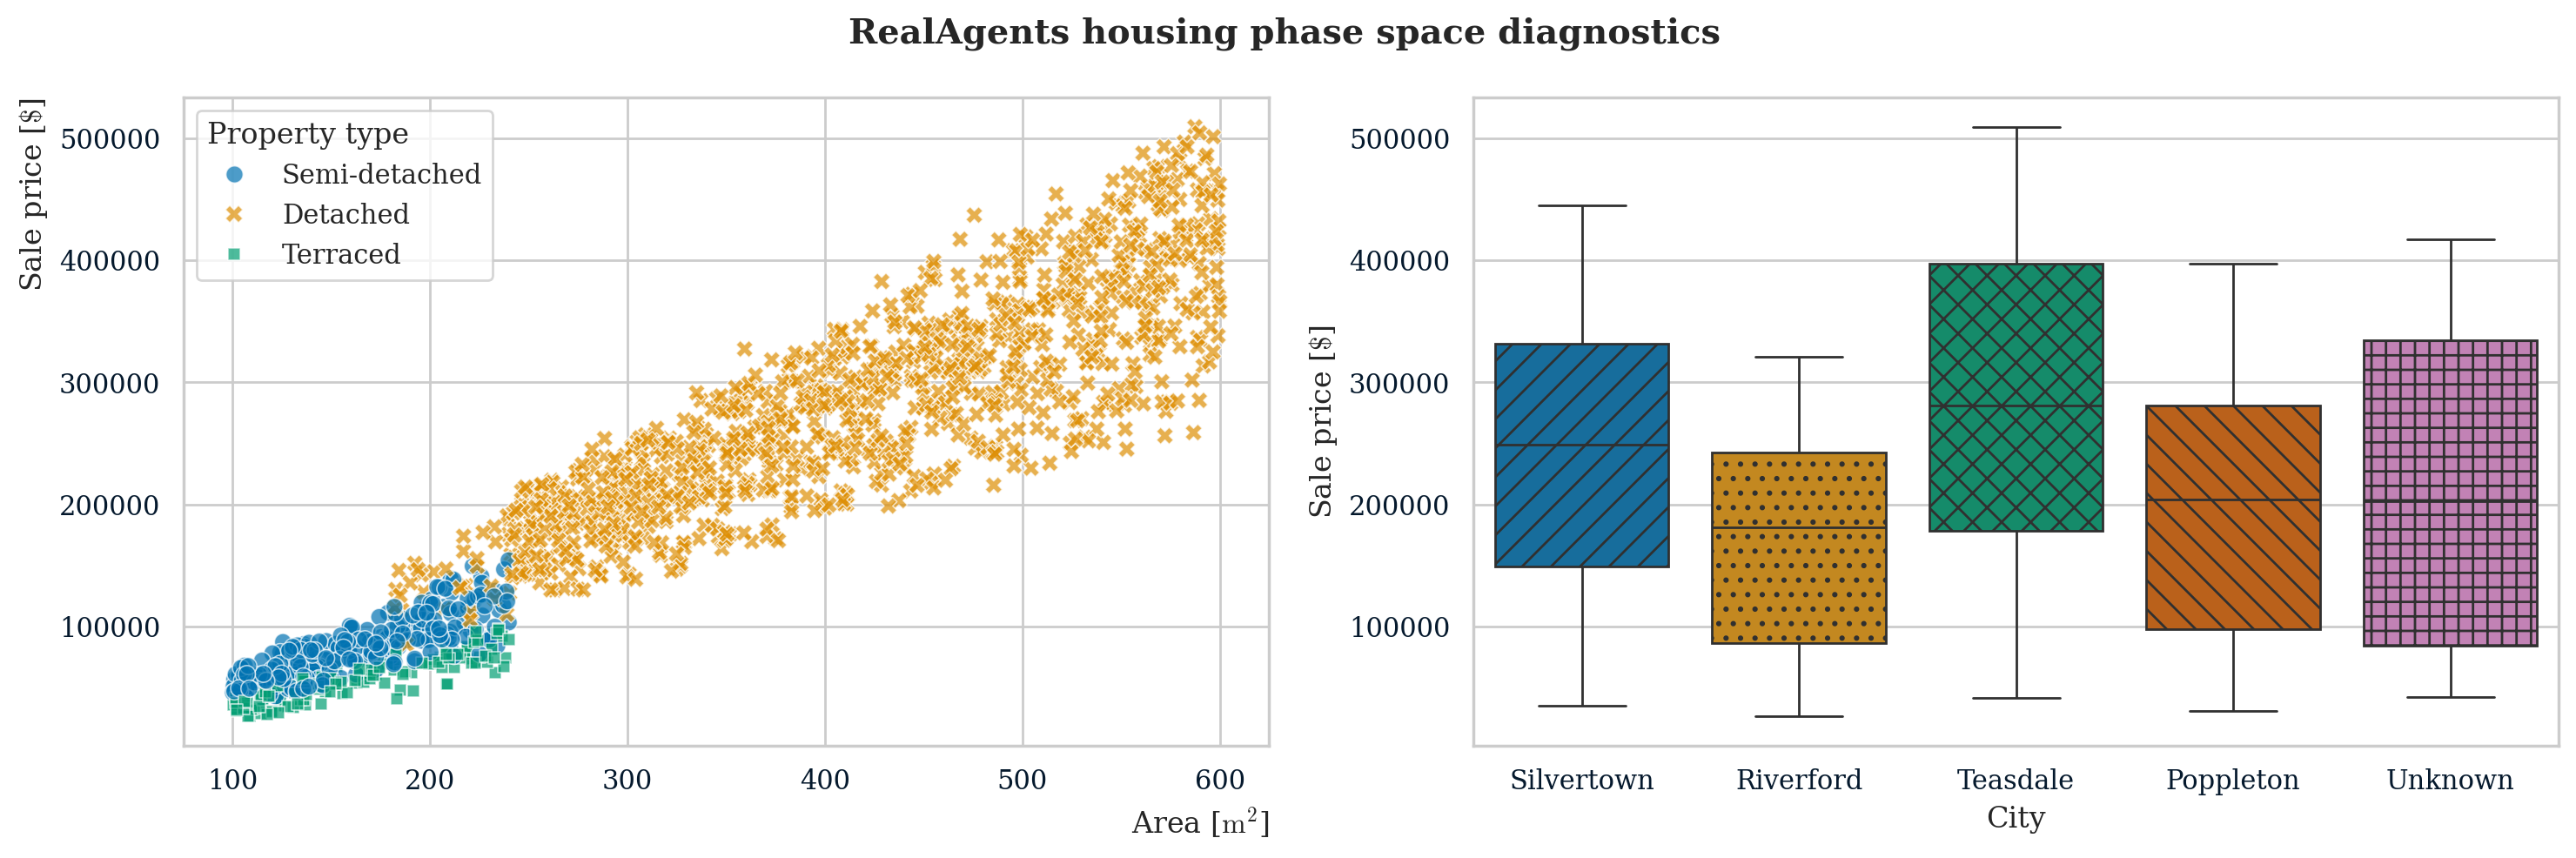

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle(r'RealAgents housing phase space diagnostics', fontweight='bold')

# 1. price vs area by house type
sns.scatterplot(
    data=clean_data, x='area', y='sale_price',
    hue='house_type', style='house_type', palette='colorblind',
    alpha=0.7, s=50, ax=axs[0]
)
axs[0].set_xlabel(r'Area [$\mathrm{m^2}$]', loc='right')
axs[0].set_ylabel(r'Sale price [$\$$]', loc='top')
axs[0].legend(title=r'Property type', frameon=True, alignment='left')

# 2. price distr. by city
box_plot = sns.boxplot(
    data=clean_data, x='city', y='sale_price',
    palette='colorblind', ax=axs[1], showfliers=False
)
hatches = ['//', '..', 'xx', '\\\\', '++']
for i, patch in enumerate(box_plot.patches):
    patch.set_hatch(hatches[i % len(hatches)])
axs[1].set_xlabel(r'City')
axs[1].set_ylabel(r'Sale price [$\$$]')

plt.tight_layout()
plt.show()

The above figure reveals the multi-dimensional nature of the pricing distribution.

The scatter plot on the left demonstrates a positive correlation between property area and sale price, but it is strictly heteroscedastic (meaning, the variance in price expands considerably at larger areas). Furthermore, the phase space cleanly stratifies by `house_type`: terraced' and semi-detached properties are rigidly bounded within the lower area-price regime, whilst detached properties dominate the upper continuum.

And the box plot on the right confirms that geographic location heavily dictates valuation. Both the median prices and their respective interquartile ranges fluctuate significantly across municipalities, with Teasdale commanding a visibly higher premium compared to Riverford.

These visual diagnostics empirically validate our earlier deduction from the bedroom aggregations. The target variable is governed by compounding, non-linear cross-term interactions (e.g., the marginal value of floor space is fundamentally dependent on both the structural property type and the geographic location).

_(Consequently, while we will establish a multiple linear regression (MLR) to serve as a strict parametric baseline in task 4, we mathematically anticipate that it will underfit these complex dynamics. An ensemble approach, capable of natively mapping non-linear topology, will undoubtedly be required to minimise the residual error in task 5.)_

# Task 4

Fit a baseline model to predict the sale price of a house.

 1. Fit your model using the data contained in “train.csv” </br></br>

 2. Use “validation.csv” to predict new values based on your model. You must return a dataframe named `base_result`, that includes `house_id` and `price`. The price column must be your predicted values.

## Baseline model
To start, we extract the predictive variables directly form the dataframe's schema. We exclude our target, `sale_price`, and `house_id`, which is just an orthogonal index that is non-predictive. We also drop `sale_date` as temporal string identifiers do not provide direct linear predictive value in standard cross-sectional housing models without further feature engineering.

Furthermore, we will dynamically partition the remaining features into continuous and categorical subsets by querying their data types.

In [14]:
# loading datasets
train_df = pd.read_csv('train.csv')
val_df = pd.read_csv('validation.csv')

# initial inspection of datasets
display(train_df.info())
display(val_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   house_id       1200 non-null   int64  
 1   city           1200 non-null   object 
 2   sale_price     1200 non-null   int64  
 3   sale_date      1200 non-null   object 
 4   months_listed  1200 non-null   float64
 5   bedrooms       1200 non-null   int64  
 6   house_type     1200 non-null   object 
 7   area           1200 non-null   float64
dtypes: float64(2), int64(3), object(3)
memory usage: 75.1+ KB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   house_id       300 non-null    int64  
 1   city           300 non-null    object 
 2   sale_date      300 non-null    object 
 3   months_listed  300 non-null    float64
 4   bedrooms       300 non-null    int64  
 5   house_type     300 non-null    object 
 6   area           300 non-null    float64
dtypes: float64(2), int64(2), object(3)
memory usage: 16.5+ KB


None

In [15]:
# defining target and non-predictive vars
target = 'sale_price'
exclude_cols = ['house_id', 'sale_date', target]

# isolating feature space
features = [col for col in train_df.columns if col not in exclude_cols]

X_train = train_df[features]
y_train = train_df[target]
X_val = val_df[features]

# separating cont. and categ. vars based on dtype
num_features = X_train.select_dtypes(include='number').columns.tolist()
cat_features = X_train.select_dtypes(include='object').columns.tolist()

# ensuring no lost features in type casting
assert len(num_features)+len(cat_features) == len(X_train.columns), 'mismatched feature dimensionality'

With the feature phase space partitioned, we construct a pre-processing transformer.

Continuous variables, `num_features`, are fed through a standard scaler to centre the mean to zero and scale the variance to unit variance, ensuring higher-magnitude features (like `area`) do not dominate the gradient updates.

Categorical variables, `cat_features`, are mapped to orthogonal binary vectors via one-hot encoding.

In [16]:
# defining the pre-proc. transformations
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ])

We then establish our baseline using a standard multiple linear regression (MLR) model. This tests the hypothesis of a strict, independent linear mapping between our transformed feature space and the final sale price.

In [17]:
# assembling baseline modelling pipeline
base_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# fitting baseline model to training data
base_model.fit(X_train, y_train)

# predicting on validation set
base_pred = base_model.predict(X_val)
base_result = pd.DataFrame({
    'house_id': val_df['house_id'],
    'price': base_pred
})

base_result.head()

,house_id,price
0,1331375,121527.827316
1,1630115,304386.625267
2,1645745,384760.100656
3,1336775,123976.268985
4,1888274,271186.199353


The baseline MLR model generated predictions for the validation set successfully, as shown in the latest output for the `base_result` dataframe. By mapping the scaled continuous and one-hot encoded categorical variables, this establishes an interpretable baseline for house prices.

However, the immense variance observed during our initial aggregations _still_ suggests that a strictly linear topology will likely underfit the multi-dimensional, interacting variables inherent to real estate pricing.

# Task 5

Fit a comparison model to predict the sale price of a house.

 1. Fit your model using the data contained in “train.csv” </br></br>

 2. Use “validation.csv” to predict new values based on your model. You must return a dataframe named `compare_result`, that includes `house_id` and `price`. The price column must be your predicted values.

## Comparison model
The linear baseline inherently assumes feature independence and a constant rate of change. However, real estate valuations are rarely strictly linear; the marginal value of an additional bedroom often depends heavily on the specific `city` or overall `area` (representing cross-term interactions).

To capture these non-linear dynamics and complex feature interactions, we will deploy a random forest regressor. By constructing an ensemble of decision trees and averaging their outputs, we mathematically reduce prediction variance and map non-linear topologies without requiring explicit polynomial feature engineering.

In [18]:
# assembling comparison modelling pipeline
compare_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=21))
])

# fitting ensemble model to training data
compare_model.fit(X_train, y_train)

# predicting on validation set
compare_pred = compare_model.predict(X_val)
compare_result = pd.DataFrame({
    'house_id': val_df['house_id'],
    'price': compare_pred
})

compare_result.head()

,house_id,price
0,1331375,81555.48
1,1630115,303397.59
2,1645745,405311.58
3,1336775,106786.51
4,1888274,268601.54


From here, we see that the random forest pipeline has successfully generated discrete predictions for the validation set, stored in the `compare_result` dataframe. Unlike the continuous algebraic outputs of the linear model, these predictions reflect the averaged consensus of an ensemble of decision trees.

This confirms that our pipeline successfully mapped the non-linear topologies of the feature space without requiring explicit manual feature engineering.

## Empirical validation
While our pipelines are complete, we cannot compute the final directly because the target values for the validation set remain hidden. To precisely prove that our models satisfy the strict tolerance ($\mathrm{RMSE<30000}$), we must mathematically estimate the out-of-sample error using the training phase space.

### $k$-fold cross-validation
We employ $k$-fold cross-validation. The provided datasets (`train.csv` having 1200 entries and `validation.csv` having 300 entries) represent an exact $80:20$ split. By selecting $k=5$, we partition the training data into five mutually exclusive subsets. Iteratively, the model trains on four folds ($80\%$) and validates on the remaining fold ($20\%$).

This choice of $k$ is deliberate: it perfectly mirrors the dimensionality of the actual train–validation split, thereby minimising pessimistic bias. Furthermore, averaging the residual errors across all five folds stabilises the variance, providing a highly robust, unbiased estimator of the models' true generalisation error before they ever touch the blind test set.

In [19]:
# calculating x-validated RMSE
## for baseline model
base_cv = -cross_val_score(base_model, X_train, y_train, scoring='neg_root_mean_squared_error', cv=5)
## for comparison model
compare_cv = -cross_val_score(compare_model, X_train, y_train, scoring='neg_root_mean_squared_error', cv=5)

print(f'Baseline MLR CV RMSE: {base_cv.mean()} +/- {base_cv.std()}')
print(f'Comparison RFR CV RMSE: {compare_cv.mean()} +/- {compare_cv.std()}')

Baseline MLR CV RMSE: 21811.434874547813 +/- 1275.1689281040058
Comparison RFR CV RMSE: 15357.287242445227 +/- 424.17764275021506


Thus, we conclude that the empirical cross-validation strictly validates our theoretical models (both baseline and comparison), with
* the baseline (MLR) model: achieving a mean CV RMSE of $21811.4\pm1275.2$, and
* the comparison (RFR) model: achieving a mean CV RMSE of $15357.3\pm424.2$.

Both models successfully satisfy the project's strict error threshold of an RMSE below 30000. Moreover, the random forest regressor proved vastly superior, reducing the residual error by over 6400 whilst also exhibiting a tighter standard deviation.

As visually diagnosed in our EDA, the real estate feature space contains severe heteroscedasticity and distinct spatial stratification. The MLR struggled to map these dynamics due to its rigid algebraic constraints. By relaxing the assumption of strict linearity, the RFR successfully modelled the complex cross-term interactions (such as the compounding value of floor area depending on the specific city and structural property type).

We recommend deploying the random forest pipeline to production. It provides a highly robust, mathematically sound predictive engine that will allow the RealAgents team to confidently optimise their listing prices and minimise time-on-market.